# GreenCart Checkout A/B Test: Analysis Notebook

**Question:** does the redesigned (simplified) checkout convert more sessions into orders than the current one?

**Answer in short:** yes. Conversion rose from **10.15% to 12.19%** (+20.1% relative, **p = 0.0021**, 95% CI for the absolute lift +0.74 to +3.34 pp). The Sample Ratio Mismatch check passed, several independent methods agree, and the gain comes from **less drop-off at the payment → order step**. Recommendation: ship, rolling out to mobile first, and keep monitoring revenue per session.

> **Note:** the data is simulated (see README). The notebook demonstrates the method end to end.

In [1]:
import os, sys
os.chdir(os.path.abspath(".." if os.path.basename(os.getcwd()) == "notebooks" else "."))
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import analysis as an
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
CTRL, TRT = "#94a3b8", "#16a34a"
an.load_db()
os.makedirs("docs", exist_ok=True)

## 1. Data and validation
One row per session. Loaded into SQLite with a defined schema (`sql/schema.sql`); all aggregation below runs as SQL.

In [2]:
df = an.q("SELECT * FROM sessions")
print(df.shape)
df.head()

(9000, 8)


,session_id,variant,device,city,session_date,converted,order_value,furthest_step
0,1,treatment,Desktop,Mumbai,2026-03-03,0,0.0,2
1,2,treatment,Mobile,Delhi,2026-03-20,0,0.0,3
2,3,treatment,Mobile,Mumbai,2026-03-15,0,0.0,2
3,4,control,Desktop,Mumbai,2026-03-01,0,0.0,2
4,5,treatment,Tablet,Delhi,2026-03-01,0,0.0,3


In [3]:
an.validate_data()

,check,issues_found,passed
0,No duplicate session_id,0,True
1,No missing values,0,True
2,Variant only control/treatment,0,True
3,Converted is 0/1,0,True
4,Order value only on converted sessions,0,True
5,Funnel step 4 equals converted,0,True
6,Dates inside experiment window,0,True


All integrity checks pass: no duplicates or missing values, valid categories, order value only on converted sessions, and the funnel agrees with the conversion flag.

## 2. Sample Ratio Mismatch
With 50/50 randomization the split should match within chance. A chi-square test flags a mismatch at p < 0.001.

In [4]:
counts, res, srm = an.overall()
print(counts.n.to_dict(), "->", f"{counts.loc['treatment','n']/counts.n.sum():.2%} in treatment")
print(f"SRM chi-square p = {srm['p_value']:.3f}  ->  mismatch: {bool(srm['mismatch'])}")

{'control': 4464, 'treatment': 4536} -> 50.40% in treatment
SRM chi-square p = 0.448  ->  mismatch: False


## 3. Experiment design: power
Planned baseline 10%, minimum detectable effect 20% relative, alpha 0.05, power 80%.

Required sessions per group: 3,841 | actual: 4,464 to 4,536


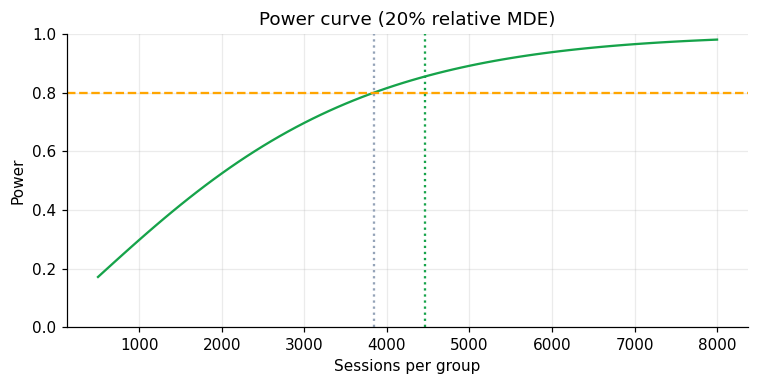

In [5]:
need = an.sample_size(0.10, 0.20)
print(f"Required sessions per group: {need:,} | actual: {counts.n.min():,} to {counts.n.max():,}")
ns = np.arange(500, 8001, 100)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(ns, [an.power_at(0.10, 0.20, n) for n in ns], color=TRT)
ax.axhline(.8, ls="--", color="orange"); ax.axvline(need, ls=":", color=CTRL); ax.axvline(counts.n.min(), ls=":", color=TRT)
ax.set(title="Power curve (20% relative MDE)", xlabel="Sessions per group", ylabel="Power", ylim=(0, 1))
fig.tight_layout(); fig.savefig("docs/power_curve.png"); plt.show()

## 4. Primary result
Two-proportion z-test (pooled variance) with an unpooled 95% CI for the difference.

p_control      0.1015
p_treatment    0.1219
abs_lift       0.0204
rel_lift       0.2014
z              3.0762
p_value        0.0021
ci_low         0.0074
ci_high        0.0334
dtype: float64


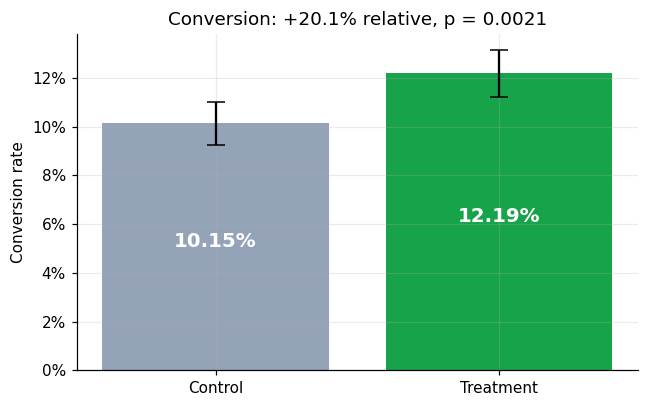

In [6]:
print(pd.Series({k: round(float(v), 4) for k, v in res.items()}))
se = lambda p, n: np.sqrt(p * (1 - p) / n)
fig, ax = plt.subplots(figsize=(6, 3.8))
vals = [res["p_control"], res["p_treatment"]]
errs = [1.96 * se(res["p_control"], counts.loc["control", "n"]), 1.96 * se(res["p_treatment"], counts.loc["treatment", "n"])]
ax.bar(["Control", "Treatment"], vals, yerr=errs, color=[CTRL, TRT], capsize=6)
for i, v in enumerate(vals): ax.text(i, v / 2, f"{v:.2%}", ha="center", fontsize=13, color="white", fontweight="bold")
ax.set(title=f"Conversion: {res['rel_lift']:+.1%} relative, p = {res['p_value']:.4f}", ylabel="Conversion rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
fig.tight_layout(); fig.savefig("docs/conversion.png"); plt.show()

## 5. Robustness
The same question answered with methods that make different assumptions. A Bayesian view is added for a direct probability statement.

In [7]:
rb = an.robustness(); display(rb)
b = an.bayes()
print(f"Bayesian: P(treatment > control) = {b['prob_better']:.1%}, expected lift {b['lift_mean']:+.1%}, 95% credible interval [{b['lift_lo']:+.1%}, {b['lift_hi']:+.1%}]")

,method,p_value,ci_low,ci_high
0,Two-proportion z-test,0.002097,0.00743,0.033440
1,Chi-square (2x2),0.002097,NaN,NaN
2,Fisher exact,0.002319,NaN,NaN
3,Permutation test,0.002050,NaN,NaN
4,Bootstrap CI,NaN,0.00752,0.033737


Bayesian: P(treatment > control) = 99.9%, expected lift +20.4%, 95% credible interval [+6.9%, +35.1%]


Every p-value is about 0.002 and the bootstrap interval matches the analytic one, so the conclusion does not depend on the test chosen.

## 6. Where did the lift come from? Checkout funnel
Built in SQL with a CTE and `LAG()`; each step-to-step conversion is z-tested.

,label,control,treatment,step_conv_control,step_conv_treatment,rel_lift,p_value
0,Cart viewed,4464,4536,NaN,NaN,NaN,NaN
1,Shipping details,3336,3393,0.7473,0.7480,0.0009,0.9387
2,Payment details,2081,2197,0.6238,0.6475,0.0380,0.0433
3,Order placed,453,553,0.2177,0.2517,0.1563,0.0087


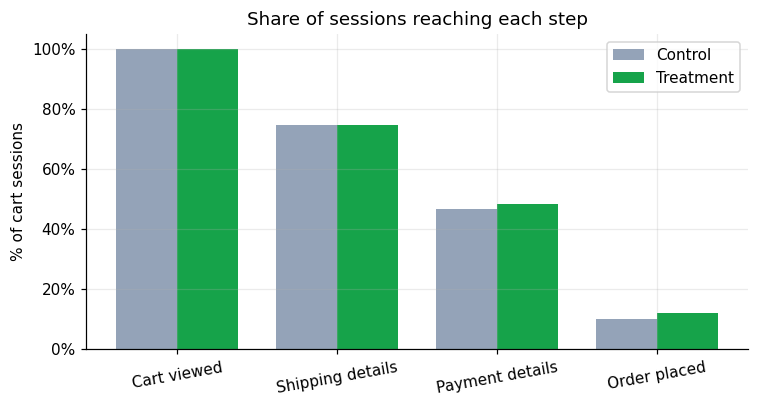

In [8]:
fn = an.funnel()
display(fn[["label", "control", "treatment", "step_conv_control", "step_conv_treatment", "rel_lift", "p_value"]].round(4))
fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(fn)); w = .38
ax.bar(x - w/2, fn.control / fn.control.iloc[0], w, label="Control", color=CTRL)
ax.bar(x + w/2, fn.treatment / fn.treatment.iloc[0], w, label="Treatment", color=TRT)
ax.set_xticks(x); ax.set_xticklabels(fn.label, rotation=10)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set(title="Share of sessions reaching each step", ylabel="% of cart sessions"); ax.legend()
fig.tight_layout(); fig.savefig("docs/funnel.png"); plt.show()

Shipping details is flat; **payment → order is the step that moves** (21.8% to 25.2%, +15.6%, p = 0.009). The redesign mainly reduces drop-off at payment.

## 7. Segments
Per-segment z-tests from SQL aggregates, with a Bonferroni-adjusted p-value because many slices are tested. Treat as exploratory.

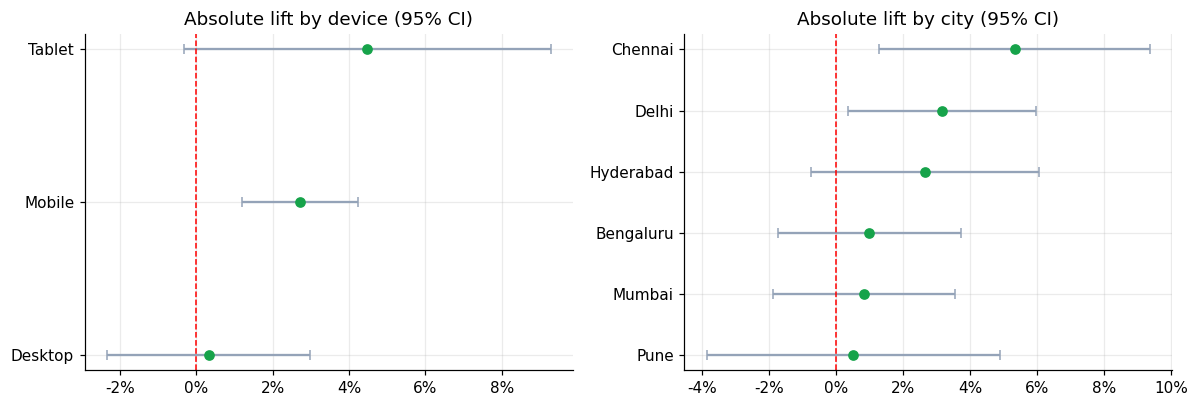

,device,sessions,rel_lift,p_value,p_adj
2,Tablet,615,0.5444,0.0715,0.2145
1,Mobile,5561,0.3489,0.0005,0.0014
0,Desktop,2824,0.0212,0.8128,1.0000


,city,sessions,rel_lift,p_value,p_adj
1,Chennai,938,0.6083,0.0105,0.0630
2,Delhi,1824,0.3527,0.0279,0.1674
3,Hyderabad,1285,0.2757,0.1296,0.7777
0,Bengaluru,2152,0.0862,0.4806,1.0000
4,Mumbai,2009,0.0795,0.5486,1.0000
5,Pune,792,0.0465,0.8211,1.0000


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col in zip(axes, ("device", "city")):
    seg = an.segment(col).sort_values("abs_lift")
    ax.errorbar(seg.abs_lift, range(len(seg)), xerr=[seg.abs_lift - seg.ci_low, seg.ci_high - seg.abs_lift],
                fmt="o", color=TRT, ecolor=CTRL, capsize=3)
    ax.axvline(0, ls="--", color="red", lw=1); ax.set_yticks(range(len(seg))); ax.set_yticklabels(seg[col])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.set_title(f"Absolute lift by {col} (95% CI)")
fig.tight_layout(); fig.savefig("docs/segments.png"); plt.show()
display(an.segment("device")[["device", "sessions", "rel_lift", "p_value", "p_adj"]].round(4))
display(an.segment("city")[["city", "sessions", "rel_lift", "p_value", "p_adj"]].round(4))

Mobile is the only segment that stays clearly significant after correction (+34.9%). Desktop is flat. City differences are mostly noise.

## 8. Over time: peeking and novelty
The cumulative p-value moves a lot early on, which is why the sample size was fixed up front. Lift by week checks for a novelty effect.

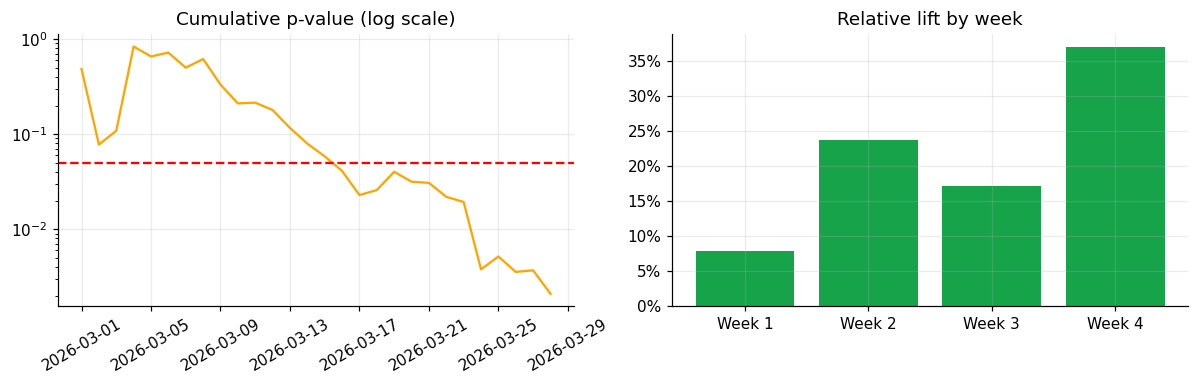

In [10]:
dly, wk = an.daily(), an.weekly()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].semilogy(pd.to_datetime(dly.session_date), dly.cum_p, color="orange"); axes[0].axhline(.05, ls="--", color="red")
axes[0].set(title="Cumulative p-value (log scale)"); axes[0].tick_params(axis="x", rotation=30)
axes[1].bar(wk.week, wk.rel_lift, color=TRT); axes[1].set(title="Relative lift by week")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout(); fig.savefig("docs/trend.png"); plt.show()

Lift is positive in every week and does not fade, so there is no sign of a novelty effect. Single weeks are small and noisy.

## 9. Guardrail: revenue per session

In [11]:
rv = an.revenue_test()
print(f"Control {rv['rps_control']:.2f}  Treatment {rv['rps_treatment']:.2f}  ({rv['rel_lift']:+.1%}, Welch t-test p = {rv['p_value']:.3f})")

Control 75.07  Treatment 85.26  (+13.6%, Welch t-test p = 0.061)


Revenue per session is up 13.6%, but not statistically significant. The guardrail requirement is only that it does not drop, so it is met; no revenue win is claimed.

## 10. Recommendation and limitations

**Ship the new checkout**, rolling out gradually with mobile first, and monitor revenue per session after launch.

**Limitations**
- The data is simulated; the effect size was built into the simulation.
- Randomization is by session, not by user, so repeat visitors are not modelled.
- Segment results are exploratory, and device × city cells are small.
- In a real test I would run at least one or two full weeks, randomize by user, reduce variance with CUPED, and add more guardrails (refunds, page speed).